
# 4. Modeling and Evaluation

This notebook evaluates six-hour-ahead PM2.5 forecasting using the model-ready dataset from Notebook 02.

The experiments include:

1. Persistence and seasonal-naive baselines.
2. Hyperparameter selection and comparison of tabular models.
3. Feature-group ablation using fixed model configurations.
4. LSTM and flattened XGBoost comparisons with 12h and 24h lookbacks.
5. Final temporal evaluation, error analysis, and block-bootstrap comparisons.

## Evaluation strategy

Two expanding-window folds are used for model selection:
- Fold 1: Train 2022–2023, validate 2023–2024.
- Fold 2: Train 2022–2024, validate 2024–2025.

The final evaluation covers September 2025–August 2026. A six-hour purge is applied at training boundaries to prevent forecast targets from crossing into subsequent periods.

RMSE is the primary evaluation metric, with MAE and R² reported as supplementary measures.

## 0. Setup and load model-ready data

In [1]:
from pathlib import Path
from copy import deepcopy
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

PROCESSED_DIR = Path("../data/processed")
OUTPUT_DIR = Path("../outputs/openmeteo_4y_final_methodology")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

target = "pm25_t_plus_6"
FORECAST_HOURS = 6
forecast_horizon = pd.Timedelta(hours=FORECAST_HOURS)

# These affect diagnostics only, not the trained model definitions.
PERMUTATION_REPEATS = 30
BOOTSTRAP_ITERATIONS = 2000

df = pd.read_pickle(
    PROCESSED_DIR / "hanoi_pm25_model_full_4y.pkl"
).sort_values("timestamp_local").reset_index(drop=True)

print("Loaded:", df.shape)
print(df["timestamp_local"].min(), "->", df["timestamp_local"].max())


Loaded: (35034, 26)
2022-09-02 00:00:00+07:00 -> 2026-08-31 17:00:00+07:00


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3544348848.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  forecast_horizon = pd.Timedelta(hours=FORECAST_HOURS)


## 1. Prespecified feature groups

In [2]:
history_features = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "pm25_lag12",
    "pm25_lag18",
    "pm25_lag24",
]

time_features = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

weather_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos",
]

core_features = (
    history_features
    + time_features
    + weather_features
)

feature_sets = {
    "History": history_features,
    "History + Time": history_features + time_features,
    "History + Weather": history_features + weather_features,
    "Core: History + Weather + Time": core_features,
    "Core + PM10": core_features + ["pm10"],
    "Core + NO2": core_features + ["no2"],
    "Full: Core + PM10 + NO2": core_features + ["pm10", "no2"],
}

for name, features in feature_sets.items():
    missing = [c for c in features if c not in df.columns]
    assert not missing, f"{name} missing columns: {missing}"
    print(f"{name}: {len(features)} features")


History: 8 features
History + Time: 14 features
History + Weather: 15 features
Core: History + Weather + Time: 21 features
Core + PM10: 22 features
Core + NO2: 22 features
Full: Core + PM10 + NO2: 23 features


The main tabular comparison uses the **21-feature Core set** (PM2.5 history, meteorology, and cyclic time features). PM10 and NO2 are evaluated separately in the feature-ablation experiment.


## 2. Expanding-window development folds and final evaluation period

In [3]:
TZ = "Asia/Ho_Chi_Minh"

FOLDS = [
    {
        "fold": "Fold 1",
        "val_start": pd.Timestamp("2023-09-01 00:00:00", tz=TZ),
        "val_end": pd.Timestamp("2024-09-01 00:00:00", tz=TZ),
    },
    {
        "fold": "Fold 2",
        "val_start": pd.Timestamp("2024-09-01 00:00:00", tz=TZ),
        "val_end": pd.Timestamp("2025-09-01 00:00:00", tz=TZ),
    },
]

TEST_START = pd.Timestamp(
    "2025-09-01 00:00:00",
    tz=TZ,
)

def get_fold_data(data, fold):
    ts = data["timestamp_local"]
    val_start = fold["val_start"]
    val_end = fold["val_end"]

    train = data[
        (ts < val_start)
        & (ts + forecast_horizon < val_start)
    ].copy()

    val = data[
        (ts >= val_start)
        & (ts < val_end)
        & (ts + forecast_horizon < val_end)
    ].copy()

    return train, val

for fold in FOLDS:
    train_fold, val_fold = get_fold_data(df, fold)

    print(
        fold["fold"],
        "| train:",
        train_fold["timestamp_local"].min(),
        "->",
        train_fold["timestamp_local"].max(),
        len(train_fold),
        "| validation:",
        val_fold["timestamp_local"].min(),
        "->",
        val_fold["timestamp_local"].max(),
        len(val_fold),
    )

final_train = df[
    (df["timestamp_local"] < TEST_START)
    & (df["timestamp_local"] + forecast_horizon < TEST_START)
].copy()

final_test = df[
    df["timestamp_local"] >= TEST_START
].copy()

print("\nFinal development train:", len(final_train))
print("Final evaluation:", len(final_test))


Fold 1 | train: 2022-09-02 00:00:00+07:00 -> 2023-08-31 17:00:00+07:00 8730 | validation: 2023-09-01 00:00:00+07:00 -> 2024-08-31 17:00:00+07:00 8778
Fold 2 | train: 2022-09-02 00:00:00+07:00 -> 2024-08-31 17:00:00+07:00 17514 | validation: 2024-09-01 00:00:00+07:00 -> 2025-08-31 17:00:00+07:00 8754

Final development train: 26274
Final evaluation: 8754


### Target distribution by annual evaluation period

In [4]:
period_rows = []

for fold in FOLDS:
    _, val_fold = get_fold_data(df, fold)

    period_rows.append({
        "Period": fold["fold"] + " validation",
        "N": len(val_fold),
        "Mean": val_fold[target].mean(),
        "Std": val_fold[target].std(),
        "Median": val_fold[target].median(),
        "Min": val_fold[target].min(),
        "Max": val_fold[target].max(),
    })

period_rows.append({
    "Period": "Final evaluation",
    "N": len(final_test),
    "Mean": final_test[target].mean(),
    "Std": final_test[target].std(),
    "Median": final_test[target].median(),
    "Min": final_test[target].min(),
    "Max": final_test[target].max(),
})

target_distribution = pd.DataFrame(period_rows)
target_distribution


,Period,N,Mean,Std,Median,Min,Max
0,Fold 1 validation,8778,37.574573,20.556227,32.6,3.3,140.6
1,Fold 2 validation,8754,50.924617,30.952612,43.3,3.0,232.8
2,Final evaluation,8754,48.779975,30.163778,40.4,3.3,186.7


## 3. Experiment A — Forecasting baselines

Two naive forecasts are evaluated on the same temporal folds:

- **Persistence:** $\hat{y}_{t+6}=PM_{2.5}(t)$.
- **Daily seasonal naive:** $\hat{y}_{t+6}=PM_{2.5}(t-18)$, the same local hour on the previous day relative to the target.


In [5]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Bias": float(np.mean(y_pred - y_true)),
    }

baseline_rows = []

for fold in FOLDS:
    _, val_fold = get_fold_data(df, fold)

    baseline_predictions = {
        "Persistence": val_fold["pm25"].to_numpy(),
        "Seasonal naive (same target hour previous day)": (
            val_fold["pm25_lag18"].to_numpy()
        ),
    }

    for method, pred in baseline_predictions.items():
        baseline_rows.append({
            "Method": method,
            "Fold": fold["fold"],
            **regression_metrics(val_fold[target], pred),
        })

baseline_cv = pd.DataFrame(baseline_rows)

baseline_summary = (
    baseline_cv
    .groupby("Method")
    .agg(
        RMSE_mean=("RMSE", "mean"),
        MAE_mean=("MAE", "mean"),
        R2_mean=("R2", "mean"),
        Bias_mean=("Bias", "mean"),
    )
    .sort_values("RMSE_mean")
    .reset_index()
)

display(baseline_cv)
display(baseline_summary)


,Method,Fold,MAE,RMSE,R2,Bias
0,Persistence,Fold 1,13.255400,18.553005,0.185312,-0.000923
1,Seasonal naive (same target hour previous day),Fold 1,13.805366,19.412375,0.108092,-0.009034
2,Persistence,Fold 2,19.621442,28.428507,0.156348,-0.008876
3,Seasonal naive (same target hour previous day),Fold 2,20.807048,30.016920,0.059438,0.029347


,Method,RMSE_mean,MAE_mean,R2_mean,Bias_mean
0,Persistence,23.490756,16.438421,0.170830,-0.004899
1,Seasonal naive (same target hour previous day),24.714647,17.306207,0.083765,0.010156


## 4. Experiment B — Tabular model comparison

All models use the Core features and the same two validation folds. Candidates are evaluated by mean validation RMSE: Linear Regression (1 configuration), Ridge (6), Random Forest (8), Extra Trees (8), and XGBoost (8). The search evaluates predefined configurations rather than a full parameter grid.


In [6]:
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    warnings.warn(
        "xgboost is not installed. "
        "XGBoost sections will be skipped."
    )

# Prespecified candidate spaces
MODEL_CANDIDATES = [
    {
        "Family": "Linear Regression",
        "Config": "OLS",
        "Params": {},
    },
]

# Ridge: regularization strength over several orders of magnitude.
for alpha in [0.1, 1, 10, 100, 500, 1000]:
    MODEL_CANDIDATES.append({
        "Family": "Ridge",
        "Config": f"alpha={alpha}",
        "Params": {
            "alpha": alpha,
        },
    })

# Random Forest:
# vary ensemble size, tree depth, leaf regularization, and feature sampling.
rf_candidates = [
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 500, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 300, "max_depth": 20, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 500, "max_depth": 20, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 300, "max_depth": 15, "min_samples_leaf": 4, "max_features": "sqrt"},
    {"n_estimators": 500, "max_depth": 15, "min_samples_leaf": 4, "max_features": "sqrt"},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 500, "max_depth": None, "min_samples_leaf": 2, "max_features": "sqrt"},
]

for i, params in enumerate(rf_candidates, start=1):
    MODEL_CANDIDATES.append({
        "Family": "Random Forest",
        "Config": f"RF-{i}",
        "Params": params,
    })

# Extra Trees:
# the same tuning logic is applied with an approximately matched budget.
et_candidates = [
    {"n_estimators": 300, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 500, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 300, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 500, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 300, "min_samples_leaf": 4, "max_features": "sqrt"},
    {"n_estimators": 500, "min_samples_leaf": 4, "max_features": "sqrt"},
    {"n_estimators": 300, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 500, "min_samples_leaf": 2, "max_features": "sqrt"},
]

for i, params in enumerate(et_candidates, start=1):
    MODEL_CANDIDATES.append({
        "Family": "Extra Trees",
        "Config": f"ET-{i}",
        "Params": params,
    })

# XGBoost:
# cover different boosting lengths, depths, learning rates, and sampling strengths.
if HAS_XGBOOST:
    xgb_candidates = [
        {
            "n_estimators": 250,
            "max_depth": 3,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        {
            "n_estimators": 400,
            "max_depth": 3,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
        },
        {
            "n_estimators": 600,
            "max_depth": 3,
            "learning_rate": 0.03,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        {
            "n_estimators": 250,
            "max_depth": 4,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        {
            "n_estimators": 400,
            "max_depth": 4,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
        },
        {
            "n_estimators": 600,
            "max_depth": 4,
            "learning_rate": 0.03,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        {
            "n_estimators": 400,
            "max_depth": 5,
            "learning_rate": 0.03,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        {
            "n_estimators": 600,
            "max_depth": 5,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
        },
    ]

    for i, params in enumerate(xgb_candidates, start=1):
        MODEL_CANDIDATES.append({
            "Family": "XGBoost",
            "Config": f"XGB-{i}",
            "Params": params,
        })

candidate_count = (
    pd.DataFrame(MODEL_CANDIDATES)
    .groupby("Family")
    .size()
    .rename("Candidate count")
    .to_frame()
)

display(candidate_count)


,Candidate count
Family,
Extra Trees,8
Linear Regression,1
Random Forest,8
Ridge,6
XGBoost,8


In [7]:
def build_tabular_model(family, params):
    params = deepcopy(params)

    if family == "Linear Regression":
        return LinearRegression()

    if family == "Ridge":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(**params)),
        ])

    if family == "Random Forest":
        return RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )

    if family == "Extra Trees":
        return ExtraTreesRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )

    if family == "XGBoost":
        if not HAS_XGBOOST:
            raise RuntimeError("XGBoost is unavailable.")

        return XGBRegressor(
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )

    raise ValueError(f"Unknown family: {family}")


### Evaluate candidate configurations across both folds


In [8]:
tabular_cv_rows = []

for candidate in MODEL_CANDIDATES:
    for fold in FOLDS:
        train_fold, val_fold = get_fold_data(df, fold)

        model = build_tabular_model(
            candidate["Family"],
            candidate["Params"],
        )

        model.fit(
            train_fold[core_features],
            train_fold[target],
        )

        pred = model.predict(
            val_fold[core_features]
        )

        tabular_cv_rows.append({
            "Family": candidate["Family"],
            "Config": candidate["Config"],
            "Params": json.dumps(
                candidate["Params"],
                sort_keys=True,
            ),
            "Fold": fold["fold"],
            **regression_metrics(
                val_fold[target],
                pred,
            ),
        })

tabular_cv_folds = pd.DataFrame(
    tabular_cv_rows
)

tabular_cv_summary = (
    tabular_cv_folds
    .groupby(
        ["Family", "Config", "Params"]
    )
    .agg(
        RMSE_mean=("RMSE", "mean"),
        MAE_mean=("MAE", "mean"),
        R2_mean=("R2", "mean"),
        Bias_mean=("Bias", "mean"),
    )
    .reset_index()
    .sort_values(
        ["Family", "RMSE_mean"]
    )
)

display(
    tabular_cv_summary
    .sort_values("RMSE_mean")
    .head(25)
)


,Family,Config,Params,RMSE_mean,MAE_mean,R2_mean,Bias_mean
28,XGBoost,XGB-6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.000558,11.232249,0.614765,-0.428516
29,XGBoost,XGB-7,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.018230,11.203720,0.614214,-0.429165
26,XGBoost,XGB-4,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.051130,11.273544,0.612494,-0.461221
25,XGBoost,XGB-3,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.100059,11.343208,0.610061,-0.433001
27,XGBoost,XGB-5,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",16.112842,11.310579,0.610004,-0.410570
30,XGBoost,XGB-8,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",16.181371,11.328211,0.606130,-0.438999
24,XGBoost,XGB-2,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",16.221392,11.427935,0.603811,-0.460984
23,XGBoost,XGB-1,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.236044,11.462480,0.603843,-0.511574
1,Extra Trees,ET-2,"{""max_features"": 1.0, ""min_samples_leaf"": 1, ""...",16.266504,11.474731,0.602034,-0.098018
3,Extra Trees,ET-4,"{""max_features"": 1.0, ""min_samples_leaf"": 2, ""...",16.267584,11.427685,0.602436,-0.302191


### Select configurations by mean validation RMSE

The lowest-RMSE configuration is retained for each model family, together with its hyperparameters.


In [9]:
best_tabular_by_family = (
    tabular_cv_summary
    .sort_values(
        ["Family", "RMSE_mean"]
    )
    .groupby(
        "Family",
        as_index=False,
    )
    .first()
    .sort_values("RMSE_mean")
    .reset_index(drop=True)
)

display(best_tabular_by_family)

selected_parameter_table = (
    best_tabular_by_family[
        [
            "Family",
            "Config",
            "Params",
            "RMSE_mean",
            "MAE_mean",
            "R2_mean",
        ]
    ]
    .copy()
)

selected_parameter_table


,Family,Config,Params,RMSE_mean,MAE_mean,R2_mean,Bias_mean
0,XGBoost,XGB-6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.000558,11.232249,0.614765,-0.428516
1,Extra Trees,ET-2,"{""max_features"": 1.0, ""min_samples_leaf"": 1, ""...",16.266504,11.474731,0.602034,-0.098018
2,Random Forest,RF-4,"{""max_depth"": 20, ""max_features"": 1.0, ""min_sa...",16.468286,11.550141,0.592455,-0.345325
3,Linear Regression,OLS,{},16.864894,12.033290,0.573226,-0.620081
4,Ridge,alpha=0.1,"{""alpha"": 0.1}",16.864901,12.033331,0.573225,-0.620074


,Family,Config,Params,RMSE_mean,MAE_mean,R2_mean
0,XGBoost,XGB-6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",16.000558,11.232249,0.614765
1,Extra Trees,ET-2,"{""max_features"": 1.0, ""min_samples_leaf"": 1, ""...",16.266504,11.474731,0.602034
2,Random Forest,RF-4,"{""max_depth"": 20, ""max_features"": 1.0, ""min_sa...",16.468286,11.550141,0.592455
3,Linear Regression,OLS,{},16.864894,12.033290,0.573226
4,Ridge,alpha=0.1,"{""alpha"": 0.1}",16.864901,12.033331,0.573225


### Validation performance by fold


Fold,Fold 1,Fold 2,Mean RMSE
Family,,,
XGBoost,12.692125,19.308990,16.000558
Extra Trees,12.884996,19.648012,16.266504
Random Forest,13.009438,19.927133,16.468286
Linear Regression,13.259764,20.470025,16.864894
Ridge,13.259791,20.470012,16.864901


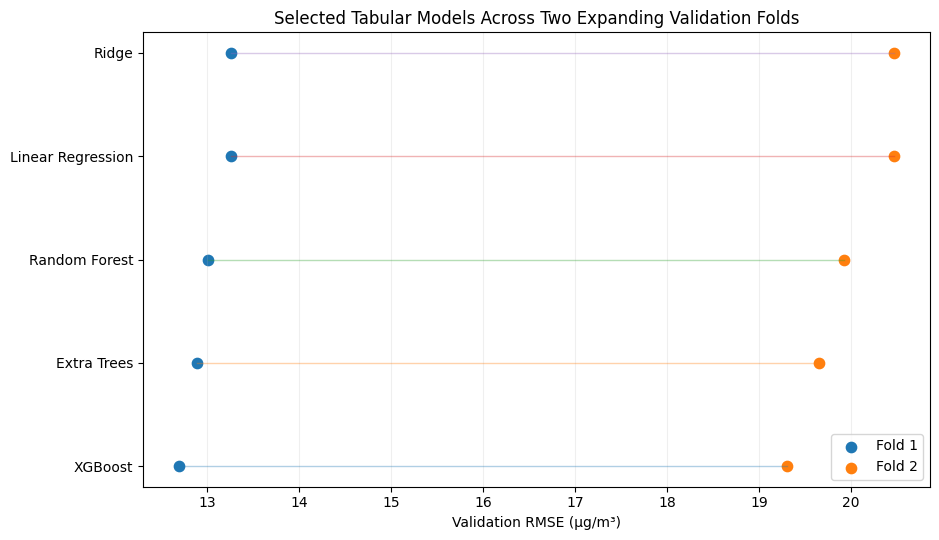

In [10]:
def plot_two_fold_rmse(
    data,
    label_col,
    title,
    order=None,
    figsize=(10, 5.5),
):
    pivot = data.pivot(
        index=label_col,
        columns="Fold",
        values="RMSE",
    )

    if order is not None:
        pivot = pivot.reindex(order)

    fold_cols = [
        c
        for c in ["Fold 1", "Fold 2"]
        if c in pivot.columns
    ]

    y_pos = np.arange(len(pivot))

    plt.figure(figsize=figsize)

    if len(fold_cols) == 2:
        for y, (_, row) in zip(
            y_pos,
            pivot.iterrows(),
        ):
            plt.plot(
                [
                    row[fold_cols[0]],
                    row[fold_cols[1]],
                ],
                [y, y],
                linewidth=1,
                alpha=0.35,
            )

    for fold_name in fold_cols:
        plt.scatter(
            pivot[fold_name],
            y_pos,
            s=55,
            label=fold_name,
        )

    plt.yticks(
        y_pos,
        pivot.index,
    )
    plt.xlabel("Validation RMSE (µg/m³)")
    plt.title(title)
    plt.legend()
    plt.grid(
        axis="x",
        alpha=0.2,
    )
    plt.tight_layout()
    plt.show()


best_tabular_fold_parts = []

for _, best_row in best_tabular_by_family.iterrows():
    family = best_row["Family"]
    config = best_row["Config"]

    part = tabular_cv_folds[
        (tabular_cv_folds["Family"] == family)
        & (tabular_cv_folds["Config"] == config)
    ].copy()

    best_tabular_fold_parts.append(part)

best_tabular_folds = pd.concat(
    best_tabular_fold_parts,
    ignore_index=True,
)

tabular_fold_table = (
    best_tabular_folds
    .pivot(
        index="Family",
        columns="Fold",
        values="RMSE",
    )
)

tabular_fold_table["Mean RMSE"] = (
    tabular_fold_table.mean(axis=1)
)

tabular_fold_table = (
    tabular_fold_table
    .sort_values("Mean RMSE")
)

display(tabular_fold_table)

plot_two_fold_rmse(
    best_tabular_folds,
    label_col="Family",
    order=tabular_fold_table.index.tolist(),
    title=(
        "Selected Tabular Models Across "
        "Two Expanding Validation Folds"
    ),
    figsize=(9.5, 5.5),
)


### Select the main tabular model

The main model is the best-performing tabular family by mean validation RMSE on the Core feature set.


In [11]:
main_tabular_ranking = (
    best_tabular_by_family
    .sort_values("RMSE_mean")
    .reset_index(drop=True)
)

main_model = (
    main_tabular_ranking
    .loc[0, "Family"]
)

main_model_params = json.loads(
    main_tabular_ranking
    .loc[0, "Params"]
)

runner_up_tabular = (
    main_tabular_ranking.loc[1, "Family"]
    if len(main_tabular_ranking) > 1
    else None
)

print("Main project model:", main_model)
print("Selected parameters:")
print(main_model_params)
print(
    "Mean validation RMSE:",
    round(
        main_tabular_ranking.loc[
            0,
            "RMSE_mean",
        ],
        3,
    ),
)


Main project model: XGBoost
Selected parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 600, 'subsample': 0.8}
Mean validation RMSE: 16.001


### Train–validation performance

For each selected tabular configuration, compare training and validation RMSE within each fold. A large gap may indicate overfitting; high errors on both splits may indicate underfitting.


,Family,Fold,Train_RMSE,Validation_RMSE,RMSE_gap,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,XGBoost,Fold 1,1.091299e+01,12.692125,1.779131,7.931776e+00,9.317147,0.821585,0.618731
2,Extra Trees,Fold 1,3.464798e-13,12.884996,12.884996,2.520028e-13,9.618056,1.000000,0.607055
4,Random Forest,Fold 1,5.075972e+00,13.009438,7.933466,3.256607e+00,9.630432,0.961401,0.599429
6,Linear Regression,Fold 1,1.682903e+01,13.259764,-3.569268,1.199942e+01,9.846797,0.575712,0.583865
8,Ridge,Fold 1,1.682903e+01,13.259791,-3.569242,1.199945e+01,9.846910,0.575712,0.583863
1,XGBoost,Fold 2,1.122367e+01,19.308990,8.085317,8.134635e+00,13.147351,0.773736,0.610799
3,Extra Trees,Fold 2,3.198700e-13,19.648012,19.648012,2.338313e-13,13.331406,1.000000,0.597012
5,Random Forest,Fold 2,4.741201e+00,19.927133,15.185932,3.116840e+00,13.469851,0.959624,0.585481
9,Ridge,Fold 2,1.506661e+01,20.470012,5.403397,1.072654e+01,14.219752,0.592265,0.562587
7,Linear Regression,Fold 2,1.506661e+01,20.470025,5.403411,1.072652e+01,14.219782,0.592265,0.562587


,Family,Train_RMSE_mean,Validation_RMSE_mean,RMSE_gap_mean,Train_R2_mean,Validation_R2_mean
0,XGBoost,1.106833e+01,16.000558,4.932224,0.797660,0.614765
1,Extra Trees,3.331749e-13,16.266504,16.266504,1.000000,0.602034
2,Random Forest,4.908586e+00,16.468286,11.559699,0.960512,0.592455
3,Linear Regression,1.594782e+01,16.864894,0.917071,0.583989,0.573226
4,Ridge,1.594782e+01,16.864901,0.917078,0.583989,0.573225


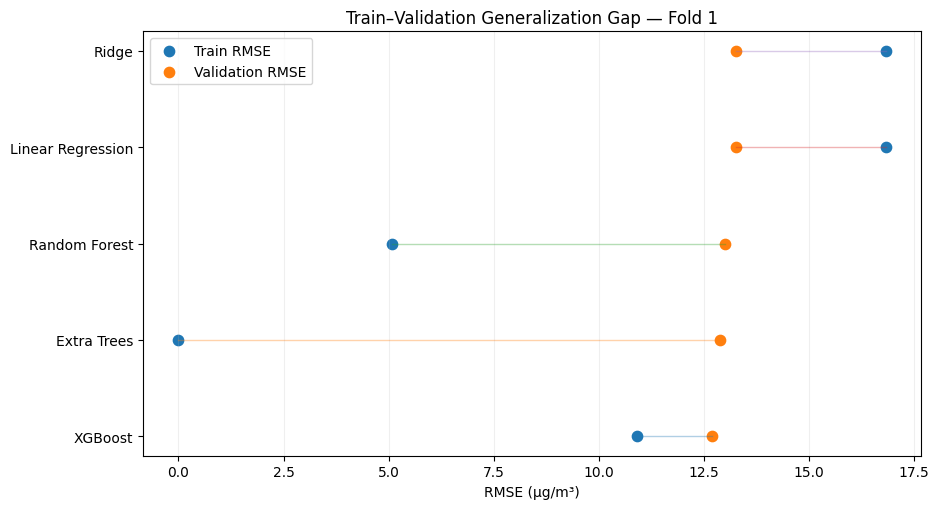

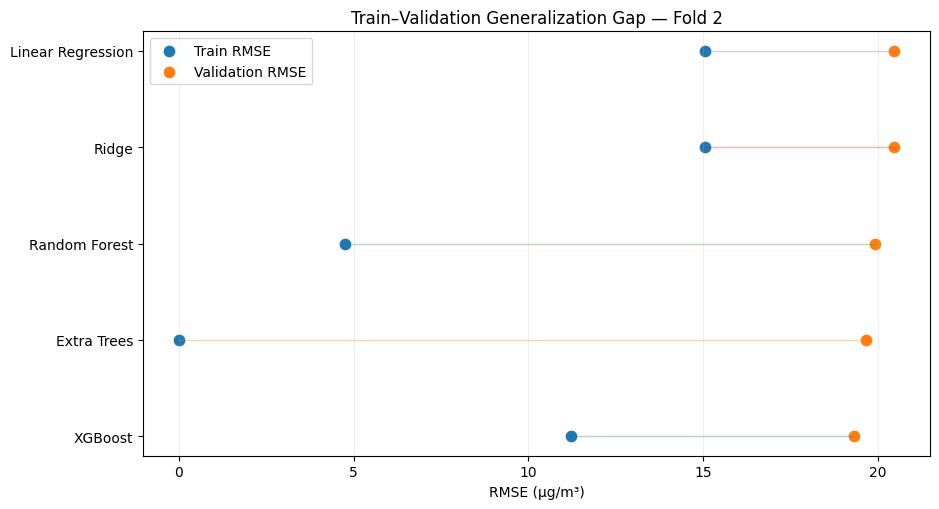

In [12]:
generalization_rows = []

for _, selected_row in best_tabular_by_family.iterrows():
    family = selected_row["Family"]
    params = json.loads(selected_row["Params"])

    for fold in FOLDS:
        train_fold, val_fold = get_fold_data(
            df,
            fold,
        )

        model = build_tabular_model(
            family,
            params,
        )

        model.fit(
            train_fold[core_features],
            train_fold[target],
        )

        train_pred = model.predict(
            train_fold[core_features]
        )
        val_pred = model.predict(
            val_fold[core_features]
        )

        train_metrics = regression_metrics(
            train_fold[target],
            train_pred,
        )
        val_metrics = regression_metrics(
            val_fold[target],
            val_pred,
        )

        generalization_rows.append({
            "Family": family,
            "Fold": fold["fold"],
            "Train_RMSE": train_metrics["RMSE"],
            "Validation_RMSE": val_metrics["RMSE"],
            "RMSE_gap": (
                val_metrics["RMSE"]
                - train_metrics["RMSE"]
            ),
            "Train_MAE": train_metrics["MAE"],
            "Validation_MAE": val_metrics["MAE"],
            "Train_R2": train_metrics["R2"],
            "Validation_R2": val_metrics["R2"],
        })

generalization_diagnostics = pd.DataFrame(
    generalization_rows
)

display(
    generalization_diagnostics
    .sort_values(["Fold", "Validation_RMSE"])
)

generalization_summary = (
    generalization_diagnostics
    .groupby("Family")
    .agg(
        Train_RMSE_mean=("Train_RMSE", "mean"),
        Validation_RMSE_mean=("Validation_RMSE", "mean"),
        RMSE_gap_mean=("RMSE_gap", "mean"),
        Train_R2_mean=("Train_R2", "mean"),
        Validation_R2_mean=("Validation_R2", "mean"),
    )
    .sort_values("Validation_RMSE_mean")
    .reset_index()
)

display(generalization_summary)

for fold_name in ["Fold 1", "Fold 2"]:
    plot_df = (
        generalization_diagnostics[
            generalization_diagnostics["Fold"]
            == fold_name
        ]
        .sort_values("Validation_RMSE")
        .reset_index(drop=True)
    )

    y_pos = np.arange(len(plot_df))

    plt.figure(figsize=(9.5, 5.2))

    for y, row in plot_df.iterrows():
        plt.plot(
            [
                row["Train_RMSE"],
                row["Validation_RMSE"],
            ],
            [y, y],
            linewidth=1,
            alpha=0.35,
        )

    plt.scatter(
        plot_df["Train_RMSE"],
        y_pos,
        s=55,
        label="Train RMSE",
    )
    plt.scatter(
        plot_df["Validation_RMSE"],
        y_pos,
        s=55,
        label="Validation RMSE",
    )

    plt.yticks(
        y_pos,
        plot_df["Family"],
    )
    plt.xlabel("RMSE (µg/m³)")
    plt.title(
        f"Train–Validation Generalization Gap — {fold_name}"
    )
    plt.legend()
    plt.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()


## 5. Experiment C — Feature-group ablation

Compare the seven predefined feature sets using Linear Regression and XGBoost. Model parameters are fixed at their Experiment B settings so that the comparison isolates changes in the input features.


In [13]:
ablation_models = {
    "Linear Regression": LinearRegression(),
}

if (
    HAS_XGBOOST
    and (
        best_tabular_by_family["Family"]
        == "XGBoost"
    ).any()
):
    xgb_selected_row = (
        best_tabular_by_family[
            best_tabular_by_family["Family"]
            == "XGBoost"
        ]
        .iloc[0]
    )

    selected_xgb_params = json.loads(
        xgb_selected_row["Params"]
    )

    ablation_models["XGBoost"] = (
        build_tabular_model(
            "XGBoost",
            selected_xgb_params,
        )
    )
else:
    selected_xgb_params = None

ablation_rows = []

for model_name, model_template in ablation_models.items():
    for feature_set_name, features in feature_sets.items():
        for fold in FOLDS:
            train_fold, val_fold = get_fold_data(
                df,
                fold,
            )

            if model_name == "Linear Regression":
                model = LinearRegression()
            else:
                model = build_tabular_model(
                    "XGBoost",
                    selected_xgb_params,
                )

            model.fit(
                train_fold[features],
                train_fold[target],
            )

            pred = model.predict(
                val_fold[features]
            )

            ablation_rows.append({
                "Model": model_name,
                "Feature set": feature_set_name,
                "Fold": fold["fold"],
                **regression_metrics(
                    val_fold[target],
                    pred,
                ),
            })

feature_ablation_folds = pd.DataFrame(
    ablation_rows
)

feature_ablation_summary = (
    feature_ablation_folds
    .groupby(
        ["Model", "Feature set"]
    )
    .agg(
        RMSE_mean=("RMSE", "mean"),
        MAE_mean=("MAE", "mean"),
        R2_mean=("R2", "mean"),
    )
    .reset_index()
    .sort_values(
        ["Model", "RMSE_mean"]
    )
)

display(feature_ablation_summary)


,Model,Feature set,RMSE_mean,MAE_mean,R2_mean
1,Linear Regression,Core + PM10,16.853269,12.073854,0.573241
3,Linear Regression,Full: Core + PM10 + NO2,16.861427,12.049555,0.573288
2,Linear Regression,Core: History + Weather + Time,16.864894,12.033290,0.573226
0,Linear Regression,Core + NO2,16.871511,12.018446,0.573334
6,Linear Regression,History + Weather,16.899145,12.005690,0.571839
5,Linear Regression,History + Time,17.727589,12.682350,0.527661
4,Linear Regression,History,17.898554,12.763855,0.520025
7,XGBoost,Core + NO2,15.928499,11.149621,0.619638
9,XGBoost,Core: History + Weather + Time,16.000558,11.232249,0.614765
8,XGBoost,Core + PM10,16.469776,11.479568,0.595756


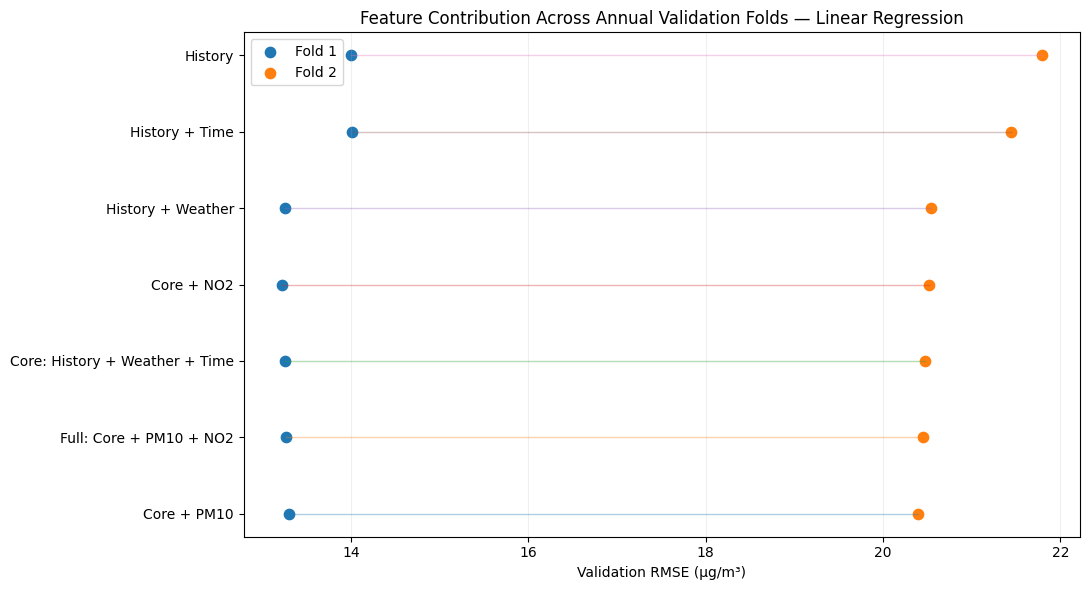

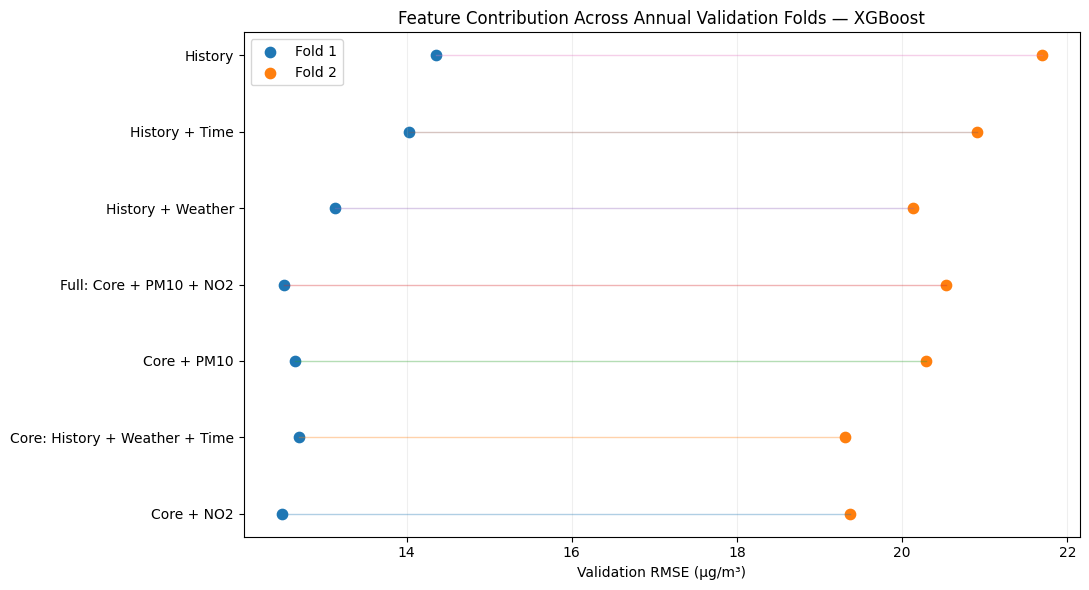

In [14]:
for model_name in feature_ablation_summary["Model"].unique():
    summary_subset = (
        feature_ablation_summary[
            feature_ablation_summary["Model"]
            == model_name
        ]
        .sort_values("RMSE_mean")
    )

    fold_subset = (
        feature_ablation_folds[
            feature_ablation_folds["Model"]
            == model_name
        ]
        .copy()
    )

    plot_two_fold_rmse(
        fold_subset,
        label_col="Feature set",
        order=(
            summary_subset[
                "Feature set"
            ].tolist()
        ),
        title=(
            "Feature Contribution Across "
            f"Annual Validation Folds — {model_name}"
        ),
        figsize=(11, 6),
    )


## 6. Experiment D — LSTM and flattened XGBoost

Compare 12-hour and 24-hour lookbacks using identical input variables. For each lookback, LSTM receives a sequence of 14 features per hour; XGBoost receives the same sequence flattened into tabular predictors.

The LSTM search tests 32/64 hidden units and dropout 0.0/0.2 at each lookback (8 configurations). Maximum training is 60 epochs, batch size 64, and early-stopping patience 5.


In [15]:
sequence_features = [
    "pm25",
    *weather_features,
    *time_features,
]

LOOKBACK_CANDIDATES = [12, 24]

LSTM_UNITS = [32, 64]
LSTM_DROPOUTS = [0.0, 0.2]

LSTM_MAX_EPOCHS = 60
LSTM_BATCH_SIZE = 64
LSTM_PATIENCE = 5
INNER_EARLY_STOP_DAYS = 60

def make_sequences(
    data,
    features,
    target_col,
    lookback,
):
    data = (
        data.sort_values(
            "timestamp_local"
        )
        .reset_index(drop=True)
    )

    X = []
    y = []
    origins = []

    feature_values = data[
        features
    ].to_numpy(dtype=np.float32)

    target_values = data[
        target_col
    ].to_numpy(dtype=np.float32)

    timestamps = data[
        "timestamp_local"
    ]

    for i in range(
        lookback - 1,
        len(data),
    ):
        start_i = (
            i - lookback + 1
        )

        window_times = (
            timestamps.iloc[
                start_i:i + 1
            ]
        )

        if not (
            window_times
            .diff()
            .dropna()
            == pd.Timedelta(hours=1)
        ).all():
            continue

        X.append(
            feature_values[
                start_i:i + 1
            ]
        )
        y.append(
            target_values[i]
        )
        origins.append(
            timestamps.iloc[i]
        )

    return (
        np.asarray(
            X,
            dtype=np.float32,
        ),
        np.asarray(
            y,
            dtype=np.float32,
        ),
        pd.DatetimeIndex(origins),
    )


def sequence_fold_indices(
    origins,
    fold,
):
    val_start = fold["val_start"]
    val_end = fold["val_end"]

    train_mask = (
        (origins < val_start)
        & (
            origins
            + forecast_horizon
            < val_start
        )
    )

    val_mask = (
        (origins >= val_start)
        & (origins < val_end)
        & (
            origins
            + forecast_horizon
            < val_end
        )
    )

    return (
        np.where(train_mask)[0],
        np.where(val_mask)[0],
    )

def inner_sequence_indices(
    origins,
    outer_boundary,
    inner_val_days=60,
):
    """
    Split an outer training period into:
      - inner training data
      - an inner chronological early-stopping holdout

    The outer validation/evaluation period is not touched here.
    """
    inner_val_start = (
        outer_boundary
        - pd.Timedelta(days=inner_val_days)
    )

    inner_train_mask = (
        (origins < inner_val_start)
        & (
            origins
            + forecast_horizon
            < inner_val_start
        )
    )

    inner_val_mask = (
        (origins >= inner_val_start)
        & (origins < outer_boundary)
        & (
            origins
            + forecast_horizon
            < outer_boundary
        )
    )

    return (
        np.where(inner_train_mask)[0],
        np.where(inner_val_mask)[0],
        inner_val_start,
    )


### Construct 12h and 24h sequences


In [16]:
sequence_data = {}

for lookback in LOOKBACK_CANDIDATES:
    X_seq, y_seq, seq_origins = make_sequences(
        df,
        sequence_features,
        target,
        lookback=lookback,
    )

    sequence_data[lookback] = {
        "X": X_seq,
        "y": y_seq,
        "origins": seq_origins,
    }

    print(
        f"Lookback={lookback}h:",
        X_seq.shape,
        "|",
        seq_origins.min(),
        "->",
        seq_origins.max(),
    )


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:64: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  == pd.Timedelta(hours=1)


Lookback=12h: (35023, 12, 14) | 2022-09-02 11:00:00+07:00 -> 2026-08-31 17:00:00+07:00


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:64: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  == pd.Timedelta(hours=1)


Lookback=24h: (35011, 24, 14) | 2022-09-02 23:00:00+07:00 -> 2026-08-31 17:00:00+07:00


### Flattened XGBoost with matched historical windows


In [17]:
sequence_cv_rows = []

if (
    HAS_XGBOOST
    and selected_xgb_params is not None
):
    for lookback in LOOKBACK_CANDIDATES:
        seq = sequence_data[lookback]

        X_all = seq["X"]
        y_all = seq["y"]
        origins = seq["origins"]

        for fold in FOLDS:
            train_idx, val_idx = (
                sequence_fold_indices(
                    origins,
                    fold,
                )
            )

            X_train_flat = (
                X_all[train_idx]
                .reshape(
                    len(train_idx),
                    -1,
                )
            )

            X_val_flat = (
                X_all[val_idx]
                .reshape(
                    len(val_idx),
                    -1,
                )
            )

            model = build_tabular_model(
                "XGBoost",
                selected_xgb_params,
            )

            model.fit(
                X_train_flat,
                y_all[train_idx],
            )

            pred = model.predict(
                X_val_flat
            )

            sequence_cv_rows.append({
                "Method": "XGBoost flattened",
                "Lookback": lookback,
                "Config": (
                    f"Selected main-XGB params; "
                    f"lookback={lookback}"
                ),
                "Fold": fold["fold"],
                **regression_metrics(
                    y_all[val_idx],
                    pred,
                ),
            })


### LSTM selection with chronological early stopping

Within each outer training fold, reserve its final 60 days to select the training epoch. Fit scalers on the inner training portion only. Then rebuild and train the model on the full outer training period for the selected number of epochs, and score it on the outer validation year.


In [18]:
HAS_TENSORFLOW = False

try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    HAS_TENSORFLOW = True
    tf.keras.utils.set_random_seed(
        RANDOM_STATE
    )

except ImportError:
    warnings.warn(
        "TensorFlow is not installed. "
        "The LSTM experiment will be skipped."
    )

def build_lstm(
    lookback,
    n_features,
    units,
    dropout,
):
    model = Sequential([
        Input(
            shape=(
                lookback,
                n_features,
            )
        ),
        LSTM(units),
        Dropout(dropout),
        Dense(1),
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
    )

    return model


In [19]:
lstm_candidate_rows = []

if HAS_TENSORFLOW:
    for lookback in LOOKBACK_CANDIDATES:
        seq = sequence_data[lookback]

        X_all = seq["X"]
        y_all = seq["y"]
        origins = seq["origins"]

        for units in LSTM_UNITS:
            for dropout in LSTM_DROPOUTS:
                config_name = (
                    f"lookback={lookback}, "
                    f"units={units}, "
                    f"dropout={dropout}"
                )

                for fold in FOLDS:
                    # OUTER split: used for unbiased candidate evaluation
                    outer_train_idx, outer_val_idx = (
                        sequence_fold_indices(
                            origins,
                            fold,
                        )
                    )

                    # INNER split: used only to determine best epoch
                    (
                        inner_train_idx,
                        inner_es_idx,
                        inner_val_start,
                    ) = inner_sequence_indices(
                        origins,
                        outer_boundary=fold["val_start"],
                        inner_val_days=INNER_EARLY_STOP_DAYS,
                    )

                    # Safety: both inner sets must belong to the outer train.
                    assert set(inner_train_idx).issubset(
                        set(outer_train_idx)
                    )
                    assert set(inner_es_idx).issubset(
                        set(outer_train_idx)
                    )

                    X_inner_train = X_all[
                        inner_train_idx
                    ]
                    X_inner_es = X_all[
                        inner_es_idx
                    ]
                    y_inner_train = y_all[
                        inner_train_idx
                    ]
                    y_inner_es = y_all[
                        inner_es_idx
                    ]

                    # Stage 1: select epoch using INNER data only
                    x_scaler_inner = StandardScaler()
                    x_scaler_inner.fit(
                        X_inner_train.reshape(
                            -1,
                            X_inner_train.shape[-1],
                        )
                    )

                    X_inner_train_scaled = (
                        x_scaler_inner
                        .transform(
                            X_inner_train.reshape(
                                -1,
                                X_inner_train.shape[-1],
                            )
                        )
                        .reshape(X_inner_train.shape)
                    )

                    X_inner_es_scaled = (
                        x_scaler_inner
                        .transform(
                            X_inner_es.reshape(
                                -1,
                                X_inner_es.shape[-1],
                            )
                        )
                        .reshape(X_inner_es.shape)
                    )

                    y_scaler_inner = StandardScaler()

                    y_inner_train_scaled = (
                        y_scaler_inner
                        .fit_transform(
                            y_inner_train.reshape(
                                -1,
                                1,
                            )
                        )
                        .ravel()
                    )

                    y_inner_es_scaled = (
                        y_scaler_inner
                        .transform(
                            y_inner_es.reshape(
                                -1,
                                1,
                            )
                        )
                        .ravel()
                    )

                    tf.keras.backend.clear_session()
                    tf.keras.utils.set_random_seed(
                        RANDOM_STATE
                    )

                    lstm_inner = build_lstm(
                        lookback=lookback,
                        n_features=(
                            X_inner_train.shape[-1]
                        ),
                        units=units,
                        dropout=dropout,
                    )

                    early_stop = EarlyStopping(
                        monitor="val_loss",
                        patience=LSTM_PATIENCE,
                        restore_best_weights=True,
                    )

                    history = lstm_inner.fit(
                        X_inner_train_scaled,
                        y_inner_train_scaled,
                        validation_data=(
                            X_inner_es_scaled,
                            y_inner_es_scaled,
                        ),
                        epochs=LSTM_MAX_EPOCHS,
                        batch_size=LSTM_BATCH_SIZE,
                        callbacks=[early_stop],
                        verbose=0,
                        shuffle=False,
                    )

                    best_epoch = int(
                        np.argmin(
                            history.history["val_loss"]
                        )
                        + 1
                    )

                    # Stage 2: rebuild and fit on FULL OUTER TRAIN
                    X_outer_train = X_all[
                        outer_train_idx
                    ]
                    X_outer_val = X_all[
                        outer_val_idx
                    ]
                    y_outer_train = y_all[
                        outer_train_idx
                    ]
                    y_outer_val = y_all[
                        outer_val_idx
                    ]

                    x_scaler_outer = StandardScaler()
                    x_scaler_outer.fit(
                        X_outer_train.reshape(
                            -1,
                            X_outer_train.shape[-1],
                        )
                    )

                    X_outer_train_scaled = (
                        x_scaler_outer
                        .transform(
                            X_outer_train.reshape(
                                -1,
                                X_outer_train.shape[-1],
                            )
                        )
                        .reshape(X_outer_train.shape)
                    )

                    X_outer_val_scaled = (
                        x_scaler_outer
                        .transform(
                            X_outer_val.reshape(
                                -1,
                                X_outer_val.shape[-1],
                            )
                        )
                        .reshape(X_outer_val.shape)
                    )

                    y_scaler_outer = StandardScaler()

                    y_outer_train_scaled = (
                        y_scaler_outer
                        .fit_transform(
                            y_outer_train.reshape(
                                -1,
                                1,
                            )
                        )
                        .ravel()
                    )

                    tf.keras.backend.clear_session()
                    tf.keras.utils.set_random_seed(
                        RANDOM_STATE
                    )

                    lstm_outer = build_lstm(
                        lookback=lookback,
                        n_features=(
                            X_outer_train.shape[-1]
                        ),
                        units=units,
                        dropout=dropout,
                    )

                    lstm_outer.fit(
                        X_outer_train_scaled,
                        y_outer_train_scaled,
                        epochs=best_epoch,
                        batch_size=LSTM_BATCH_SIZE,
                        verbose=0,
                        shuffle=False,
                    )

                    pred_scaled = (
                        lstm_outer
                        .predict(
                            X_outer_val_scaled,
                            verbose=0,
                        )
                        .ravel()
                    )

                    pred = (
                        y_scaler_outer
                        .inverse_transform(
                            pred_scaled.reshape(
                                -1,
                                1,
                            )
                        )
                        .ravel()
                    )

                    row = {
                        "Method": "LSTM",
                        "Lookback": lookback,
                        "Units": units,
                        "Dropout": dropout,
                        "Config": config_name,
                        "Fold": fold["fold"],
                        "Inner early-stop start": inner_val_start,
                        "Inner train N": len(inner_train_idx),
                        "Inner early-stop N": len(inner_es_idx),
                        "Outer train N": len(outer_train_idx),
                        "Outer validation N": len(outer_val_idx),
                        "Best epoch": best_epoch,
                        **regression_metrics(
                            y_outer_val,
                            pred,
                        ),
                    }

                    sequence_cv_rows.append(row)
                    lstm_candidate_rows.append(row)


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:138: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  - pd.Timedelta(days=inner_val_days)
/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:138: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  - pd.Timedelta(days=inner_val_days)
/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:138: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  - pd.Timedelta(days=inner_val_d

### Select LSTM configuration by validation RMSE


In [20]:
sequence_cv_folds = pd.DataFrame(
    sequence_cv_rows
)

lstm_cv_summary = pd.DataFrame()
best_lstm_config = None

if HAS_TENSORFLOW and lstm_candidate_rows:
    lstm_cv_folds = pd.DataFrame(
        lstm_candidate_rows
    )

    lstm_cv_summary = (
        lstm_cv_folds
        .groupby(
            [
                "Lookback",
                "Units",
                "Dropout",
                "Config",
            ]
        )
        .agg(
            RMSE_mean=("RMSE", "mean"),
            MAE_mean=("MAE", "mean"),
            R2_mean=("R2", "mean"),
            Best_epoch_median=(
                "Best epoch",
                "median",
            ),
        )
        .reset_index()
        .sort_values("RMSE_mean")
    )

    display(lstm_cv_summary)

    best_lstm_config = (
        lstm_cv_summary.iloc[0]
    )

    print("Selected LSTM configuration:")
    display(
        best_lstm_config.to_frame().T
    )
else:
    print("LSTM tuning was skipped.")


,Lookback,Units,Dropout,Config,RMSE_mean,MAE_mean,R2_mean,Best_epoch_median
2,12,64,0.0,"lookback=12, units=64, dropout=0.0",17.225940,12.271254,0.554646,4.5
7,24,64,0.2,"lookback=24, units=64, dropout=0.2",17.480991,12.436563,0.541938,4.0
0,12,32,0.0,"lookback=12, units=32, dropout=0.0",17.500133,12.495677,0.542317,4.0
6,24,64,0.0,"lookback=24, units=64, dropout=0.0",17.503151,12.441679,0.537403,5.5
3,12,64,0.2,"lookback=12, units=64, dropout=0.2",17.580044,12.523280,0.534069,3.0
4,24,32,0.0,"lookback=24, units=32, dropout=0.0",17.653261,12.549341,0.532569,4.0
1,12,32,0.2,"lookback=12, units=32, dropout=0.2",17.756531,12.712252,0.526716,4.5
5,24,32,0.2,"lookback=24, units=32, dropout=0.2",17.914558,12.756522,0.518644,4.5


Selected LSTM configuration:


,Lookback,Units,Dropout,Config,RMSE_mean,MAE_mean,R2_mean,Best_epoch_median
2,12,64,0.0,"lookback=12, units=64, dropout=0.0",17.22594,12.271254,0.554646,4.5


### Compare sequence models by lookback

Compare the best validated LSTM configuration with flattened XGBoost separately for 12h and 24h windows.


In [21]:
sequence_comparison_rows = []

# XGBoost summary for each lookback.
if not sequence_cv_folds.empty:
    xgb_seq_summary = (
        sequence_cv_folds[
            sequence_cv_folds["Method"]
            == "XGBoost flattened"
        ]
        .groupby(
            ["Method", "Lookback"]
        )
        .agg(
            RMSE_mean=("RMSE", "mean"),
            MAE_mean=("MAE", "mean"),
            R2_mean=("R2", "mean"),
        )
        .reset_index()
    )

    sequence_comparison_rows.extend(
        xgb_seq_summary.to_dict(
            orient="records"
        )
    )

# Best LSTM configuration within each lookback.
if not lstm_cv_summary.empty:
    best_lstm_each_lookback = (
        lstm_cv_summary
        .sort_values("RMSE_mean")
        .groupby(
            "Lookback",
            as_index=False,
        )
        .first()
    )

    for _, row in (
        best_lstm_each_lookback
        .iterrows()
    ):
        sequence_comparison_rows.append({
            "Method": "LSTM",
            "Lookback": int(
                row["Lookback"]
            ),
            "RMSE_mean": (
                row["RMSE_mean"]
            ),
            "MAE_mean": (
                row["MAE_mean"]
            ),
            "R2_mean": (
                row["R2_mean"]
            ),
        })

sequence_comparison = (
    pd.DataFrame(
        sequence_comparison_rows
    )
    .sort_values(
        ["Lookback", "RMSE_mean"]
    )
    .reset_index(drop=True)
)

display(sequence_comparison)


,Method,Lookback,RMSE_mean,MAE_mean,R2_mean
0,XGBoost flattened,12,16.373670,11.543931,0.594605
1,LSTM,12,17.225940,12.271254,0.554646
2,XGBoost flattened,24,15.950583,11.139048,0.617734
3,LSTM,24,17.480991,12.436563,0.541938


## 7. Development results

Summarize baseline, tabular, and sequence validation results before fitting models on the complete development period.


In [22]:
development_rows = []

for _, row in baseline_summary.iterrows():
    development_rows.append({
        "Method": row["Method"],
        "Category": "Baseline",
        "RMSE_mean": row["RMSE_mean"],
        "MAE_mean": row["MAE_mean"],
        "R2_mean": row["R2_mean"],
    })

for _, row in best_tabular_by_family.iterrows():
    development_rows.append({
        "Method": row["Family"],
        "Category": "Main tabular model",
        "RMSE_mean": row["RMSE_mean"],
        "MAE_mean": row["MAE_mean"],
        "R2_mean": row["R2_mean"],
    })

development_leaderboard = (
    pd.DataFrame(
        development_rows
    )
    .sort_values("RMSE_mean")
    .reset_index(drop=True)
)

display(development_leaderboard)

print("\nFrozen main project model:")
print(main_model)
print(main_model_params)

if best_lstm_config is not None:
    print("\nFrozen LSTM configuration:")
    display(
        best_lstm_config
        .to_frame()
        .T
    )


,Method,Category,RMSE_mean,MAE_mean,R2_mean
0,XGBoost,Main tabular model,16.000558,11.232249,0.614765
1,Extra Trees,Main tabular model,16.266504,11.474731,0.602034
2,Random Forest,Main tabular model,16.468286,11.550141,0.592455
3,Linear Regression,Main tabular model,16.864894,12.033290,0.573226
4,Ridge,Main tabular model,16.864901,12.033331,0.573225
5,Persistence,Baseline,23.490756,16.438421,0.170830
6,Seasonal naive (same target hour previous day),Baseline,24.714647,17.306207,0.083765



Frozen main project model:
XGBoost
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 600, 'subsample': 0.8}

Frozen LSTM configuration:


,Lookback,Units,Dropout,Config,RMSE_mean,MAE_mean,R2_mean,Best_epoch_median
2,12,64,0.0,"lookback=12, units=64, dropout=0.0",17.22594,12.271254,0.554646,4.5


## 8. Final temporal evaluation

Refit selected models on development data through August 2025 and evaluate on September 2025–August 2026. Report all candidate model families alongside the baselines and sequence controls.


In [23]:
final_predictions = {}

# ---------------------------------------------------------------
# Baselines
# ---------------------------------------------------------------
final_predictions["Persistence"] = (
    final_test["pm25"].to_numpy()
)

final_predictions[
    "Seasonal naive (same target hour previous day)"
] = final_test[
    "pm25_lag18"
].to_numpy()

final_evaluation_rows = []

for method, pred in final_predictions.items():
    final_evaluation_rows.append({
        "Method": method,
        "Category": "Baseline",
        **regression_metrics(
            final_test[target],
            pred,
        ),
    })

# ---------------------------------------------------------------
# Frozen best configuration from every tabular family
# ---------------------------------------------------------------
best_tabular_configs = {}

for _, row in best_tabular_by_family.iterrows():
    family = row["Family"]

    params = json.loads(
        row["Params"]
    )

    best_tabular_configs[
        family
    ] = params

    model = build_tabular_model(
        family,
        params,
    )

    model.fit(
        final_train[core_features],
        final_train[target],
    )

    pred = model.predict(
        final_test[core_features]
    )

    final_predictions[
        family
    ] = pred

    final_evaluation_rows.append({
        "Method": family,
        "Category": "Tabular model",
        **regression_metrics(
            final_test[target],
            pred,
        ),
    })


### Final flattened-XGBoost sequence controls

In [24]:
sequence_final_predictions = {}

if (
    HAS_XGBOOST
    and selected_xgb_params is not None
):
    for lookback in LOOKBACK_CANDIDATES:
        seq = sequence_data[lookback]

        X_all = seq["X"]
        y_all = seq["y"]
        origins = seq["origins"]

        seq_train_idx = np.where(
            (origins < TEST_START)
            & (
                origins
                + forecast_horizon
                < TEST_START
            )
        )[0]

        seq_test_idx = np.where(
            origins >= TEST_START
        )[0]

        X_train_flat = (
            X_all[seq_train_idx]
            .reshape(
                len(seq_train_idx),
                -1,
            )
        )

        X_test_flat = (
            X_all[seq_test_idx]
            .reshape(
                len(seq_test_idx),
                -1,
            )
        )

        model = build_tabular_model(
            "XGBoost",
            selected_xgb_params,
        )

        model.fit(
            X_train_flat,
            y_all[seq_train_idx],
        )

        pred = model.predict(
            X_test_flat
        )

        method_name = (
            f"XGBoost flattened "
            f"({lookback}h)"
        )

        sequence_final_predictions[
            method_name
        ] = {
            "pred": pred,
            "y_true": y_all[
                seq_test_idx
            ],
            "origins": origins[
                seq_test_idx
            ],
        }

        final_evaluation_rows.append({
            "Method": method_name,
            "Category": "Sequence control",
            **regression_metrics(
                y_all[seq_test_idx],
                pred,
            ),
        })


### Final LSTM fit

Use the selected LSTM architecture from development validation. Choose its epoch count with a 60-day inner holdout at the end of the development period, then refit on the full development period before evaluation.


In [25]:
lstm_final_info = None

if (
    HAS_TENSORFLOW
    and best_lstm_config is not None
):
    selected_lookback = int(
        best_lstm_config["Lookback"]
    )
    selected_units = int(
        best_lstm_config["Units"]
    )
    selected_dropout = float(
        best_lstm_config["Dropout"]
    )

    seq = sequence_data[
        selected_lookback
    ]

    X_all = seq["X"]
    y_all = seq["y"]
    origins = seq["origins"]

    # Final outer train / evaluation indices
    seq_train_idx = np.where(
        (origins < TEST_START)
        & (
            origins
            + forecast_horizon
            < TEST_START
        )
    )[0]

    seq_test_idx = np.where(
        origins >= TEST_START
    )[0]

    # INNER final-development split for epoch selection only
    (
        final_inner_train_idx,
        final_inner_es_idx,
        final_inner_val_start,
    ) = inner_sequence_indices(
        origins,
        outer_boundary=TEST_START,
        inner_val_days=INNER_EARLY_STOP_DAYS,
    )

    assert set(final_inner_train_idx).issubset(
        set(seq_train_idx)
    )
    assert set(final_inner_es_idx).issubset(
        set(seq_train_idx)
    )

    X_inner_train = X_all[
        final_inner_train_idx
    ]
    X_inner_es = X_all[
        final_inner_es_idx
    ]
    y_inner_train = y_all[
        final_inner_train_idx
    ]
    y_inner_es = y_all[
        final_inner_es_idx
    ]

    x_scaler_inner = StandardScaler()
    x_scaler_inner.fit(
        X_inner_train.reshape(
            -1,
            X_inner_train.shape[-1],
        )
    )

    X_inner_train_scaled = (
        x_scaler_inner
        .transform(
            X_inner_train.reshape(
                -1,
                X_inner_train.shape[-1],
            )
        )
        .reshape(X_inner_train.shape)
    )

    X_inner_es_scaled = (
        x_scaler_inner
        .transform(
            X_inner_es.reshape(
                -1,
                X_inner_es.shape[-1],
            )
        )
        .reshape(X_inner_es.shape)
    )

    y_scaler_inner = StandardScaler()

    y_inner_train_scaled = (
        y_scaler_inner
        .fit_transform(
            y_inner_train.reshape(
                -1,
                1,
            )
        )
        .ravel()
    )

    y_inner_es_scaled = (
        y_scaler_inner
        .transform(
            y_inner_es.reshape(
                -1,
                1,
            )
        )
        .ravel()
    )

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(
        RANDOM_STATE
    )

    lstm_epoch_selector = build_lstm(
        lookback=selected_lookback,
        n_features=(
            X_inner_train.shape[-1]
        ),
        units=selected_units,
        dropout=selected_dropout,
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=LSTM_PATIENCE,
        restore_best_weights=True,
    )

    final_epoch_history = (
        lstm_epoch_selector.fit(
            X_inner_train_scaled,
            y_inner_train_scaled,
            validation_data=(
                X_inner_es_scaled,
                y_inner_es_scaled,
            ),
            epochs=LSTM_MAX_EPOCHS,
            batch_size=LSTM_BATCH_SIZE,
            callbacks=[early_stop],
            verbose=0,
            shuffle=False,
        )
    )

    selected_epochs = int(
        np.argmin(
            final_epoch_history.history[
                "val_loss"
            ]
        )
        + 1
    )

    # Refit from scratch on ALL pre-evaluation development data
    X_train_seq = X_all[
        seq_train_idx
    ]
    X_test_seq = X_all[
        seq_test_idx
    ]
    y_train_seq = y_all[
        seq_train_idx
    ]
    y_test_seq = y_all[
        seq_test_idx
    ]

    x_scaler = StandardScaler()
    x_scaler.fit(
        X_train_seq.reshape(
            -1,
            X_train_seq.shape[-1],
        )
    )

    X_train_scaled = (
        x_scaler
        .transform(
            X_train_seq.reshape(
                -1,
                X_train_seq.shape[-1],
            )
        )
        .reshape(X_train_seq.shape)
    )

    X_test_scaled = (
        x_scaler
        .transform(
            X_test_seq.reshape(
                -1,
                X_test_seq.shape[-1],
            )
        )
        .reshape(X_test_seq.shape)
    )

    y_scaler = StandardScaler()
    y_train_scaled = (
        y_scaler
        .fit_transform(
            y_train_seq.reshape(
                -1,
                1,
            )
        )
        .ravel()
    )

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(
        RANDOM_STATE
    )

    lstm_final = build_lstm(
        lookback=selected_lookback,
        n_features=(
            X_train_seq.shape[-1]
        ),
        units=selected_units,
        dropout=selected_dropout,
    )

    lstm_final.fit(
        X_train_scaled,
        y_train_scaled,
        epochs=selected_epochs,
        batch_size=LSTM_BATCH_SIZE,
        verbose=0,
        shuffle=False,
    )

    pred_scaled = (
        lstm_final
        .predict(
            X_test_scaled,
            verbose=0,
        )
        .ravel()
    )

    pred_lstm = (
        y_scaler
        .inverse_transform(
            pred_scaled.reshape(
                -1,
                1,
            )
        )
        .ravel()
    )

    method_name = (
        f"LSTM selected "
        f"({selected_lookback}h)"
    )

    sequence_final_predictions[
        method_name
    ] = {
        "pred": pred_lstm,
        "y_true": y_test_seq,
        "origins": origins[
            seq_test_idx
        ],
    }

    final_evaluation_rows.append({
        "Method": method_name,
        "Category": "Sequence model",
        **regression_metrics(
            y_test_seq,
            pred_lstm,
        ),
    })

    lstm_final_info = {
        "Lookback": selected_lookback,
        "Units": selected_units,
        "Dropout": selected_dropout,
        "Inner early-stop start": final_inner_val_start,
        "Epochs selected from inner holdout": selected_epochs,
    }

    print(
        "Final LSTM configuration:",
        lstm_final_info,
    )


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_56937/3966927103.py:138: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  - pd.Timedelta(days=inner_val_days)


Final LSTM configuration: {'Lookback': 12, 'Units': 64, 'Dropout': 0.0, 'Inner early-stop start': Timestamp('2025-07-03 00:00:00+0700', tz='Asia/Ho_Chi_Minh'), 'Epochs selected from inner holdout': 13}


,Method,Category,MAE,RMSE,R2,Bias,RMSE_skill_vs_persistence_%,MAE_skill_vs_persistence_%
0,XGBoost,Tabular model,12.770671,18.296185,0.632041,-1.497859,39.594620,39.001800
1,XGBoost flattened (24h),Sequence control,12.897090,18.434075,0.626474,-1.324403,39.139373,38.397967
2,Extra Trees,Tabular model,13.175991,18.885081,0.607973,-0.674764,37.650363,37.065817
3,Random Forest,Tabular model,13.267788,19.035682,0.601696,-0.790200,37.153150,36.627355
4,XGBoost flattened (12h),Sequence control,13.524659,19.108833,0.598629,-1.873461,36.911641,35.400428
5,Ridge,Tabular model,14.137258,20.031877,0.558916,-1.347191,33.864186,32.474394
6,Linear Regression,Tabular model,14.137320,20.031952,0.558913,-1.347183,33.863937,32.474097
7,LSTM selected (12h),Sequence model,15.805971,22.129084,0.461724,4.689630,26.940193,24.503903
8,Seasonal naive (same target hour previous day),Baseline,19.711035,28.294658,0.119991,-0.054261,6.584377,5.851644
9,Persistence,Baseline,20.936143,30.289000,-0.008435,-0.045099,0.000000,0.000000


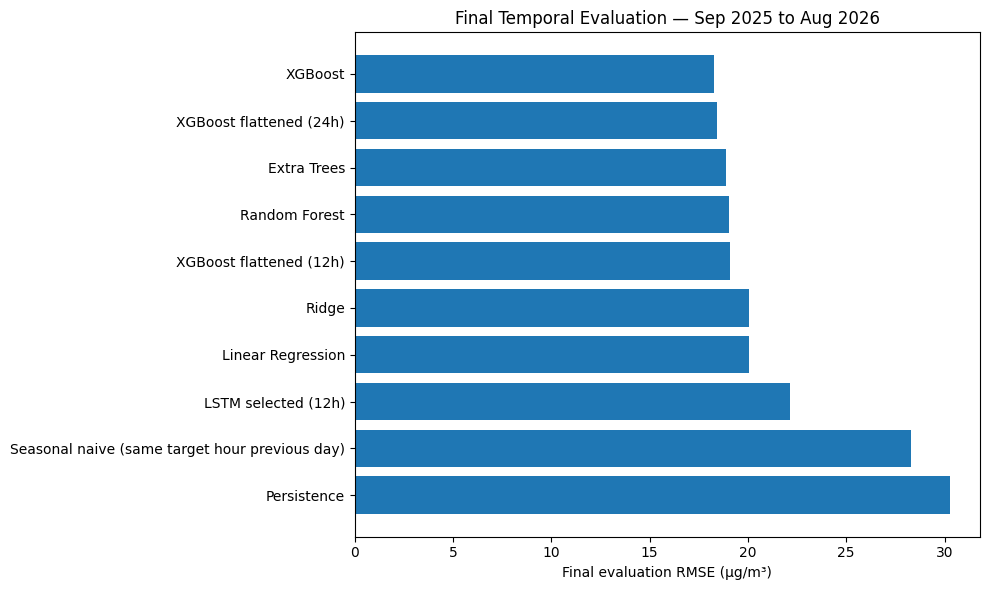

In [26]:
final_evaluation = (
    pd.DataFrame(
        final_evaluation_rows
    )
    .sort_values("RMSE")
    .reset_index(drop=True)
)

persistence_rmse = (
    final_evaluation.loc[
        final_evaluation["Method"]
        == "Persistence",
        "RMSE",
    ]
    .iloc[0]
)

persistence_mae = (
    final_evaluation.loc[
        final_evaluation["Method"]
        == "Persistence",
        "MAE",
    ]
    .iloc[0]
)

final_evaluation[
    "RMSE_skill_vs_persistence_%"
] = (
    (
        persistence_rmse
        - final_evaluation["RMSE"]
    )
    / persistence_rmse
    * 100
)

final_evaluation[
    "MAE_skill_vs_persistence_%"
] = (
    (
        persistence_mae
        - final_evaluation["MAE"]
    )
    / persistence_mae
    * 100
)

display(final_evaluation)

plt.figure(figsize=(10, 6))
plt.barh(
    final_evaluation["Method"],
    final_evaluation["RMSE"],
)
plt.gca().invert_yaxis()
plt.xlabel("Final evaluation RMSE (µg/m³)")
plt.title(
    "Final Temporal Evaluation — "
    "Sep 2025 to Aug 2026"
)
plt.tight_layout()
plt.show()


## 9. Main-model diagnostics

Inspect daily tracking, predicted versus observed values, monthly errors, errors by PM2.5 level, and permutation importance.


In [27]:
test_results = (
    final_test[
        ["timestamp_local", target]
    ]
    .copy()
)

for method, pred in final_predictions.items():
    if len(pred) == len(test_results):
        test_results[
            method
        ] = pred

assert main_model in test_results.columns

main_eval_row = (
    final_evaluation[
        final_evaluation["Method"]
        == main_model
    ]
)

print(
    "Main project model:",
    main_model,
)
print(
    "Selected hyperparameters:",
    main_model_params,
)
display(main_eval_row)


Main project model: XGBoost
Selected hyperparameters: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 600, 'subsample': 0.8}


,Method,Category,MAE,RMSE,R2,Bias,RMSE_skill_vs_persistence_%,MAE_skill_vs_persistence_%
0,XGBoost,Tabular model,12.770671,18.296185,0.632041,-1.497859,39.59462,39.0018


### 9.1 Actual vs predicted daily mean

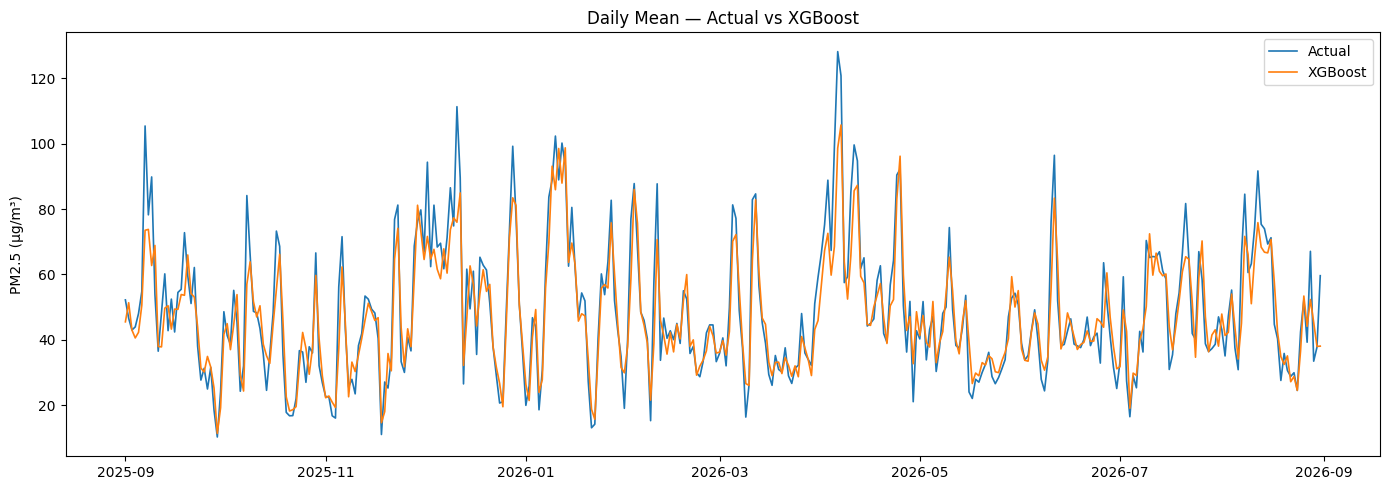

In [28]:
daily_main = (
    test_results
    .set_index(
        "timestamp_local"
    )[
        [target, main_model]
    ]
    .resample("D")
    .mean()
)

plt.figure(figsize=(14, 5))
plt.plot(
    daily_main.index,
    daily_main[target],
    label="Actual",
    linewidth=1.2,
)
plt.plot(
    daily_main.index,
    daily_main[main_model],
    label=main_model,
    linewidth=1.2,
)
plt.ylabel("PM2.5 (µg/m³)")
plt.title(
    f"Daily Mean — Actual vs {main_model}"
)
plt.legend()
plt.tight_layout()
plt.show()


### 9.2 Actual vs predicted scatter

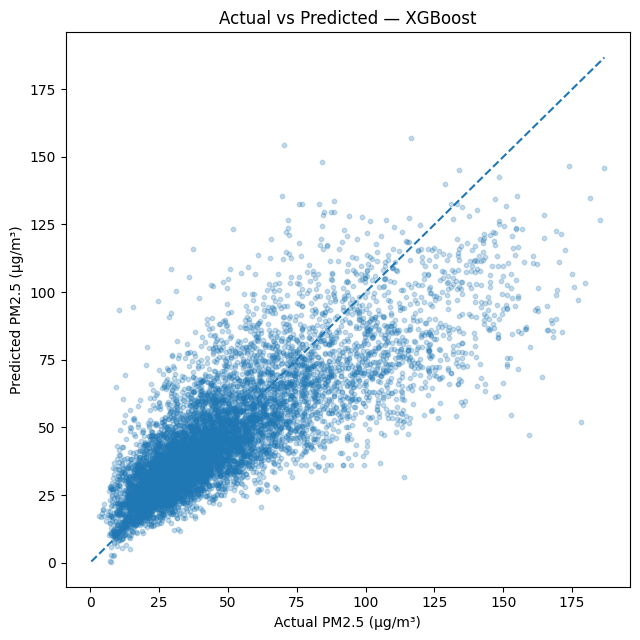

In [29]:
y_true = test_results[target]
y_pred = test_results[main_model]

plt.figure(figsize=(6.5, 6.5))
plt.scatter(
    y_true,
    y_pred,
    s=10,
    alpha=0.25,
)

lo = min(
    y_true.min(),
    y_pred.min(),
)
hi = max(
    y_true.max(),
    y_pred.max(),
)

plt.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title(
    f"Actual vs Predicted — {main_model}"
)
plt.tight_layout()
plt.show()


### 9.3 Error by calendar month

,MAE,N,RMSE
month,,,
1,13.161642,744,18.861722
2,11.395793,672,15.973568
3,9.725269,744,13.186556
4,16.363797,720,21.944333
5,9.203839,744,13.018006
6,11.469146,720,15.836999
7,13.279717,744,18.460752
8,14.940829,738,22.344363
9,14.261061,720,21.291600


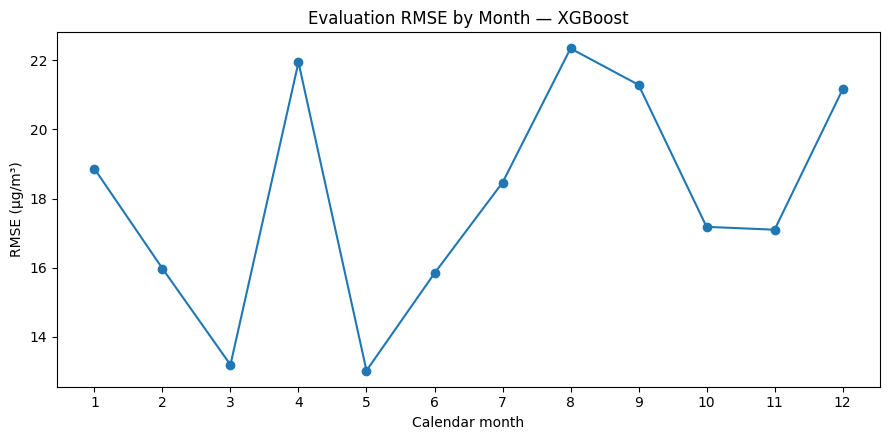

In [30]:
monthly_error = (
    test_results.copy()
)

monthly_error["month"] = (
    monthly_error[
        "timestamp_local"
    ].dt.month
)

monthly_error["abs_error"] = np.abs(
    monthly_error[main_model]
    - monthly_error[target]
)

monthly_error["sq_error"] = (
    monthly_error[main_model]
    - monthly_error[target]
) ** 2

error_by_month = (
    monthly_error
    .groupby("month")
    .agg(
        MAE=("abs_error", "mean"),
        MSE=("sq_error", "mean"),
        N=(target, "size"),
    )
)

error_by_month["RMSE"] = np.sqrt(
    error_by_month["MSE"]
)

error_by_month = (
    error_by_month
    .drop(columns="MSE")
)

display(error_by_month)

plt.figure(figsize=(9, 4.5))
plt.plot(
    error_by_month.index,
    error_by_month["RMSE"],
    marker="o",
)
plt.xticks(range(1, 13))
plt.xlabel("Calendar month")
plt.ylabel("RMSE (µg/m³)")
plt.title(
    f"Evaluation RMSE by Month — "
    f"{main_model}"
)
plt.tight_layout()
plt.show()


### 9.4 Error across PM2.5 levels

Use target quantiles from the development period to define pollution bands, then evaluate errors within those bands on the final period.


,MAE,N,Mean_target,RMSE
Target band,,,,
≤ train median,8.612118,4001,25.780755,12.056743
50–75th pct,9.547475,2105,45.726793,12.818703
75–90th pct,14.210490,1403,66.059943,17.558111
> train 90th pct,29.961939,1245,108.380803,35.515487


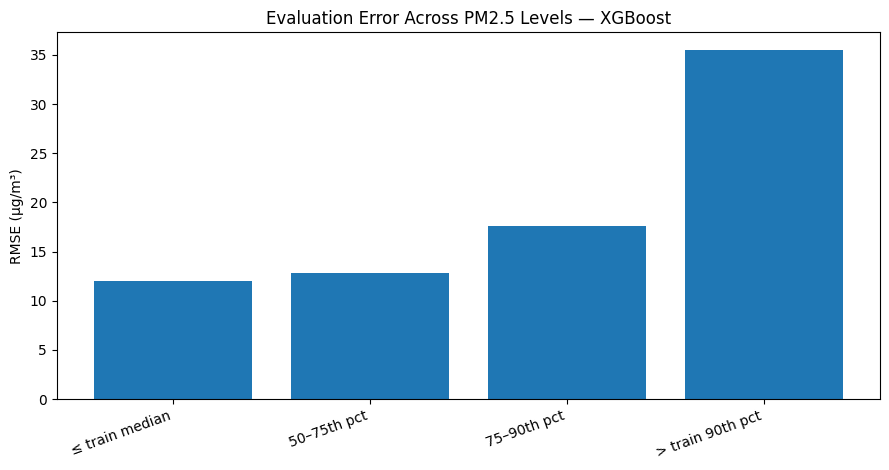

In [31]:
q50 = final_train[target].quantile(
    0.50
)
q75 = final_train[target].quantile(
    0.75
)
q90 = final_train[target].quantile(
    0.90
)

def target_band(x):
    if x <= q50:
        return "≤ train median"
    if x <= q75:
        return "50–75th pct"
    if x <= q90:
        return "75–90th pct"
    return "> train 90th pct"

tail_df = test_results.copy()

tail_df["Target band"] = (
    tail_df[target]
    .map(target_band)
)

tail_df["abs_error"] = np.abs(
    tail_df[main_model]
    - tail_df[target]
)

tail_df["sq_error"] = (
    tail_df[main_model]
    - tail_df[target]
) ** 2

band_order = [
    "≤ train median",
    "50–75th pct",
    "75–90th pct",
    "> train 90th pct",
]

error_by_band = (
    tail_df
    .groupby(
        "Target band",
        observed=False,
    )
    .agg(
        MAE=("abs_error", "mean"),
        MSE=("sq_error", "mean"),
        N=(target, "size"),
        Mean_target=(target, "mean"),
    )
    .reindex(band_order)
)

error_by_band["RMSE"] = np.sqrt(
    error_by_band["MSE"]
)

error_by_band = (
    error_by_band
    .drop(columns="MSE")
)

display(error_by_band)

plt.figure(figsize=(9, 4.8))
plt.bar(
    error_by_band.index,
    error_by_band["RMSE"],
)
plt.ylabel("RMSE (µg/m³)")
plt.title(
    f"Evaluation Error Across "
    f"PM2.5 Levels — {main_model}"
)
plt.xticks(
    rotation=20,
    ha="right",
)
plt.tight_layout()
plt.show()


### 9.5 Permutation importance

,Feature,Importance_mean,Importance_std
0,pm25,14.470160,0.155090
1,pm25_lag18,3.656282,0.075701
2,wind_speed_10m,2.325821,0.079385
3,hour_sin,2.050630,0.056002
4,hour_cos,1.166453,0.040570
5,relative_humidity_2m,1.077791,0.021357
6,pm25_lag24,0.824258,0.040169
7,wind_dir_cos,0.690437,0.036936
8,pm25_lag1,0.675408,0.029632
9,pm25_lag2,0.591358,0.029834


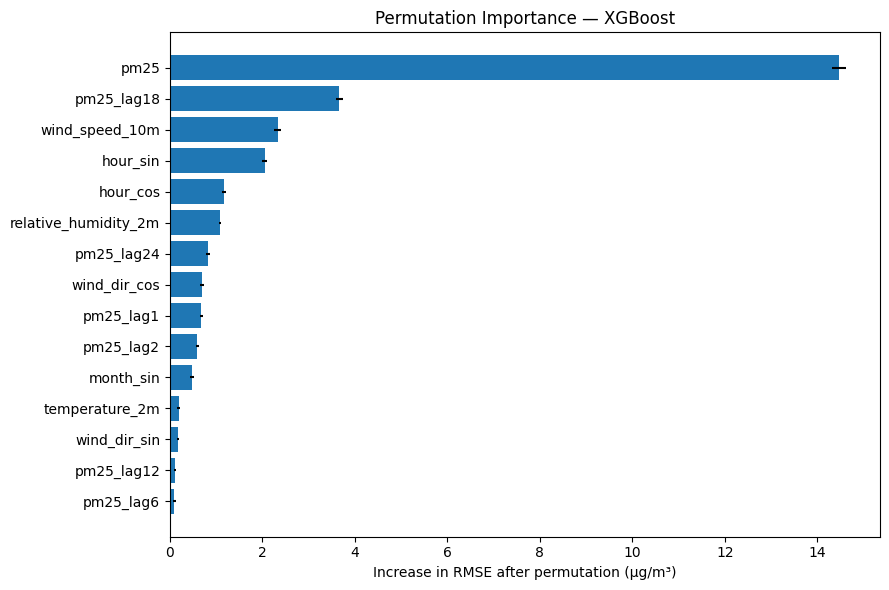

In [32]:
final_fitted_tabular_models = {}

for family, params in (
    best_tabular_configs.items()
):
    model = build_tabular_model(
        family,
        params,
    )

    model.fit(
        final_train[core_features],
        final_train[target],
    )

    final_fitted_tabular_models[
        family
    ] = model

primary_tabular_model = (
    final_fitted_tabular_models[
        main_model
    ]
)

perm = permutation_importance(
    primary_tabular_model,
    final_test[core_features],
    final_test[target],
    scoring="neg_root_mean_squared_error",
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_df = (
    pd.DataFrame({
        "Feature": core_features,
        "Importance_mean": (
            perm.importances_mean
        ),
        "Importance_std": (
            perm.importances_std
        ),
    })
    .sort_values(
        "Importance_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    importance_df.head(15)
)

plot_imp = (
    importance_df
    .head(15)
    .sort_values(
        "Importance_mean",
        ascending=True,
    )
)

plt.figure(figsize=(9, 6))
plt.barh(
    plot_imp["Feature"],
    plot_imp["Importance_mean"],
    xerr=plot_imp["Importance_std"],
)
plt.xlabel(
    "Increase in RMSE "
    "after permutation (µg/m³)"
)
plt.title(
    f"Permutation Importance — "
    f"{main_model}"
)
plt.tight_layout()
plt.show()


## 10. Block-bootstrap comparisons

Use a 24-hour moving-block bootstrap (2,000 resamples) to estimate uncertainty in the RMSE difference between the main tabular model and its runner-up. Also compare LSTM and flattened XGBoost at the selected lookback.


In [33]:
def block_bootstrap_rmse_difference(
    y_true,
    pred_primary,
    pred_challenger,
    block_size=24,
    n_boot=2000,
    random_state=42,
):
    rng = np.random.default_rng(
        random_state
    )

    y_true = np.asarray(y_true)
    pred_primary = np.asarray(
        pred_primary
    )
    pred_challenger = np.asarray(
        pred_challenger
    )

    n = len(y_true)
    max_start = n - block_size
    starts = np.arange(
        max_start + 1
    )

    diffs = []

    for _ in range(n_boot):
        sampled_idx = []

        while len(sampled_idx) < n:
            start = rng.choice(
                starts
            )
            sampled_idx.extend(
                range(
                    start,
                    start + block_size,
                )
            )

        sampled_idx = np.asarray(
            sampled_idx[:n]
        )

        rmse_primary = np.sqrt(
            mean_squared_error(
                y_true[sampled_idx],
                pred_primary[
                    sampled_idx
                ],
            )
        )

        rmse_challenger = np.sqrt(
            mean_squared_error(
                y_true[sampled_idx],
                pred_challenger[
                    sampled_idx
                ],
            )
        )

        # Positive delta = primary has lower RMSE.
        diffs.append(
            rmse_challenger
            - rmse_primary
        )

    diffs = np.asarray(diffs)

    return {
        "Mean_delta_RMSE": diffs.mean(),
        "CI_2.5%": np.quantile(
            diffs,
            0.025,
        ),
        "CI_97.5%": np.quantile(
            diffs,
            0.975,
        ),
    }


tabular_bootstrap_result = None

if (
    runner_up_tabular is not None
    and main_model
    in test_results.columns
    and runner_up_tabular
    in test_results.columns
):
    tabular_bootstrap_result = (
        block_bootstrap_rmse_difference(
            test_results[target],
            test_results[main_model],
            test_results[
                runner_up_tabular
            ],
            block_size=24,
            n_boot=BOOTSTRAP_ITERATIONS,
            random_state=RANDOM_STATE,
        )
    )

    print(
        "Main tabular model:",
        main_model,
    )
    print(
        "Tabular runner-up:",
        runner_up_tabular,
    )
    print(
        tabular_bootstrap_result
    )


sequence_bootstrap_result = None

if best_lstm_config is not None:
    selected_lookback = int(
        best_lstm_config["Lookback"]
    )

    xgb_seq_name = (
        f"XGBoost flattened "
        f"({selected_lookback}h)"
    )
    lstm_seq_name = (
        f"LSTM selected "
        f"({selected_lookback}h)"
    )

    if (
        xgb_seq_name
        in sequence_final_predictions
        and lstm_seq_name
        in sequence_final_predictions
    ):
        seq_true = (
            sequence_final_predictions[
                lstm_seq_name
            ]["y_true"]
        )

        sequence_bootstrap_result = (
            block_bootstrap_rmse_difference(
                seq_true,
                sequence_final_predictions[
                    xgb_seq_name
                ]["pred"],
                sequence_final_predictions[
                    lstm_seq_name
                ]["pred"],
                block_size=24,
                n_boot=BOOTSTRAP_ITERATIONS,
                random_state=(
                    RANDOM_STATE + 1
                ),
            )
        )

        print("\nSequence comparison")
        print(
            "Primary:",
            xgb_seq_name,
        )
        print(
            "Challenger:",
            lstm_seq_name,
        )
        print(
            sequence_bootstrap_result
        )


Main tabular model: XGBoost
Tabular runner-up: Extra Trees
{'Mean_delta_RMSE': np.float64(0.6009203084508608), 'CI_2.5%': np.float64(0.33497856560114514), 'CI_97.5%': np.float64(0.884858785552081)}

Sequence comparison
Primary: XGBoost flattened (12h)
Challenger: LSTM selected (12h)
{'Mean_delta_RMSE': np.float64(3.0489150111512435), 'CI_2.5%': np.float64(2.0941158426210116), 'CI_97.5%': np.float64(3.994184889694171)}


## 11. Save experiment outputs


In [34]:
baseline_cv.to_csv(
    OUTPUT_DIR / "baseline_cv.csv",
    index=False,
)

baseline_summary.to_csv(
    OUTPUT_DIR / "baseline_summary.csv",
    index=False,
)

tabular_cv_folds.to_csv(
    OUTPUT_DIR / "hyperparameter_cv_folds.csv",
    index=False,
)

tabular_cv_summary.to_csv(
    OUTPUT_DIR / "hyperparameter_cv_summary.csv",
    index=False,
)

best_tabular_by_family.to_csv(
    OUTPUT_DIR / "selected_parameters_by_family.csv",
    index=False,
)

selected_parameter_table.to_csv(
    OUTPUT_DIR / "selected_parameter_table.csv",
    index=False,
)

feature_ablation_folds.to_csv(
    OUTPUT_DIR / "feature_ablation_folds.csv",
    index=False,
)

feature_ablation_summary.to_csv(
    OUTPUT_DIR / "feature_ablation_summary.csv",
    index=False,
)

if not sequence_cv_folds.empty:
    sequence_cv_folds.to_csv(
        OUTPUT_DIR / "sequence_cv_folds.csv",
        index=False,
    )

if not lstm_cv_summary.empty:
    lstm_cv_summary.to_csv(
        OUTPUT_DIR / "lstm_hyperparameter_summary.csv",
        index=False,
    )

if not sequence_comparison.empty:
    sequence_comparison.to_csv(
        OUTPUT_DIR / "sequence_comparison.csv",
        index=False,
    )

final_evaluation.to_csv(
    OUTPUT_DIR / "final_evaluation.csv",
    index=False,
)

test_results.to_csv(
    OUTPUT_DIR / "final_predictions_main_frame.csv",
    index=False,
)

error_by_month.to_csv(
    OUTPUT_DIR / "error_by_month.csv"
)

error_by_band.to_csv(
    OUTPUT_DIR / "error_by_target_band.csv"
)

importance_df.to_csv(
    OUTPUT_DIR / "permutation_importance.csv",
    index=False,
)

target_distribution.to_csv(
    OUTPUT_DIR / "target_distribution_by_period.csv",
    index=False,
)

print(
    "Saved outputs to:",
    OUTPUT_DIR,
)

generalization_diagnostics.to_csv(
    OUTPUT_DIR / "generalization_diagnostics_by_fold.csv",
    index=False,
)

generalization_summary.to_csv(
    OUTPUT_DIR / "generalization_summary.csv",
    index=False,
)


Saved outputs to: ../outputs/openmeteo_4y_final_methodology


## 12. Experiment summary


In [35]:
conclusion_rows = []

# A — baseline
best_baseline = (
    baseline_summary
    .sort_values("RMSE_mean")
    .iloc[0]
)

conclusion_rows.append({
    "Experiment": "A — Baselines",
    "Evidence": (
        f"Best naive baseline: "
        f"{best_baseline['Method']} "
        f"(mean validation RMSE="
        f"{best_baseline['RMSE_mean']:.2f})."
    ),
})

# B — main tabular model + hyperparameters
main_dev = (
    best_tabular_by_family[
        best_tabular_by_family[
            "Family"
        ]
        == main_model
    ]
    .iloc[0]
)

conclusion_rows.append({
    "Experiment": (
        "B — Hyperparameter selection "
        "and main model"
    ),
    "Evidence": (
        f"{main_model} selected with "
        f"params={main_model_params}; "
        f"mean validation RMSE="
        f"{main_dev['RMSE_mean']:.2f}."
    ),
})

# C — feature contribution
ablation_reference = (
    "XGBoost"
    if "XGBoost"
    in feature_ablation_summary[
        "Model"
    ].unique()
    else "Linear Regression"
)

ablation_ref = (
    feature_ablation_summary[
        feature_ablation_summary[
            "Model"
        ]
        == ablation_reference
    ]
)

history_rmse = (
    ablation_ref.loc[
        ablation_ref[
            "Feature set"
        ]
        == "History",
        "RMSE_mean",
    ]
    .iloc[0]
)

weather_rmse = (
    ablation_ref.loc[
        ablation_ref[
            "Feature set"
        ]
        == "History + Weather",
        "RMSE_mean",
    ]
    .iloc[0]
)

weather_gain = (
    (
        history_rmse
        - weather_rmse
    )
    / history_rmse
    * 100
)

conclusion_rows.append({
    "Experiment": "C — Feature contribution",
    "Evidence": (
        f"{ablation_reference}: "
        f"History RMSE={history_rmse:.2f}; "
        f"History+Weather RMSE="
        f"{weather_rmse:.2f}; "
        f"RMSE reduction="
        f"{weather_gain:.1f}%."
    ),
})

# D — sequence
if best_lstm_config is not None:
    conclusion_rows.append({
        "Experiment": "D — Sequence extension",
        "Evidence": (
            "Selected LSTM: "
            f"lookback="
            f"{int(best_lstm_config['Lookback'])}h, "
            f"units="
            f"{int(best_lstm_config['Units'])}, "
            f"dropout="
            f"{float(best_lstm_config['Dropout'])}; "
            f"mean validation RMSE="
            f"{best_lstm_config['RMSE_mean']:.2f}."
        ),
    })

# E — final evaluation
main_final = (
    final_evaluation[
        final_evaluation[
            "Method"
        ]
        == main_model
    ]
    .iloc[0]
)

conclusion_rows.append({
    "Experiment": "E — Final temporal evaluation",
    "Evidence": (
        f"{main_model}: "
        f"RMSE={main_final['RMSE']:.2f}, "
        f"MAE={main_final['MAE']:.2f}, "
        f"R²={main_final['R2']:.3f}, "
        f"RMSE skill vs persistence="
        f"{main_final['RMSE_skill_vs_persistence_%']:.1f}%."
    ),
})

experiment_conclusions = pd.DataFrame(
    conclusion_rows
)

display(experiment_conclusions)

experiment_conclusions.to_csv(
    OUTPUT_DIR / "experiment_conclusions.csv",
    index=False,
)


,Experiment,Evidence
0,A — Baselines,Best naive baseline: Persistence (mean validat...
1,B — Hyperparameter selection and main model,XGBoost selected with params={'colsample_bytre...
2,C — Feature contribution,XGBoost: History RMSE=18.03; History+Weather R...
3,D — Sequence extension,"Selected LSTM: lookback=12h, units=64, dropout..."
4,E — Final temporal evaluation,"XGBoost: RMSE=18.30, MAE=12.77, R²=0.632, RMSE..."


### Results-to-presentation mapping


In [36]:
presentation_map = pd.DataFrame([
    {
        "Lecturer requirement": "Prediction / analysis problem",
        "Notebook evidence": "Research objective + t+6 target + Experiments A–E",
    },
    {
        "Lecturer requirement": "Data after preprocessing",
        "Notebook evidence": "Notebook 02 + target distribution by temporal period",
    },
    {
        "Lecturer requirement": "Your model and related SOTA models",
        "Notebook evidence": (
            f"Main model = {main_model}; "
            "explicit selected hyperparameters; "
            "LSTM sequence benchmark; "
            "literature context"
        ),
    },
    {
        "Lecturer requirement": "Building your model",
        "Notebook evidence": (
            "Temporal validation → constrained hyperparameter search → "
            "feature contribution → sequence extension"
        ),
    },
    {
        "Lecturer requirement": "Testing your model",
        "Notebook evidence": "Final frozen evaluation on Sep 2025–Aug 2026",
    },
    {
        "Lecturer requirement": "Performance analysis and comparison",
        "Notebook evidence": (
            "All-family comparison + monthly errors + PM2.5 bands + "
            "permutation importance + block bootstrap"
        ),
    },
    {
        "Lecturer requirement": "Lessons learned",
        "Notebook evidence": (
            "Feature value, model complexity, sequence comparison, "
            "failure in high-PM2.5 regimes"
        ),
    },
])

display(presentation_map)


,Lecturer requirement,Notebook evidence
0,Prediction / analysis problem,Research objective + t+6 target + Experiments A–E
1,Data after preprocessing,Notebook 02 + target distribution by temporal ...
2,Your model and related SOTA models,Main model = XGBoost; explicit selected hyperp...
3,Building your model,Temporal validation → constrained hyperparamet...
4,Testing your model,Final frozen evaluation on Sep 2025–Aug 2026
5,Performance analysis and comparison,All-family comparison + monthly errors + PM2.5...
6,Lessons learned,"Feature value, model complexity, sequence comp..."
